# Exploration: Technical Probability Calibration

Rows after filtering: 1,905
Wells included: 575


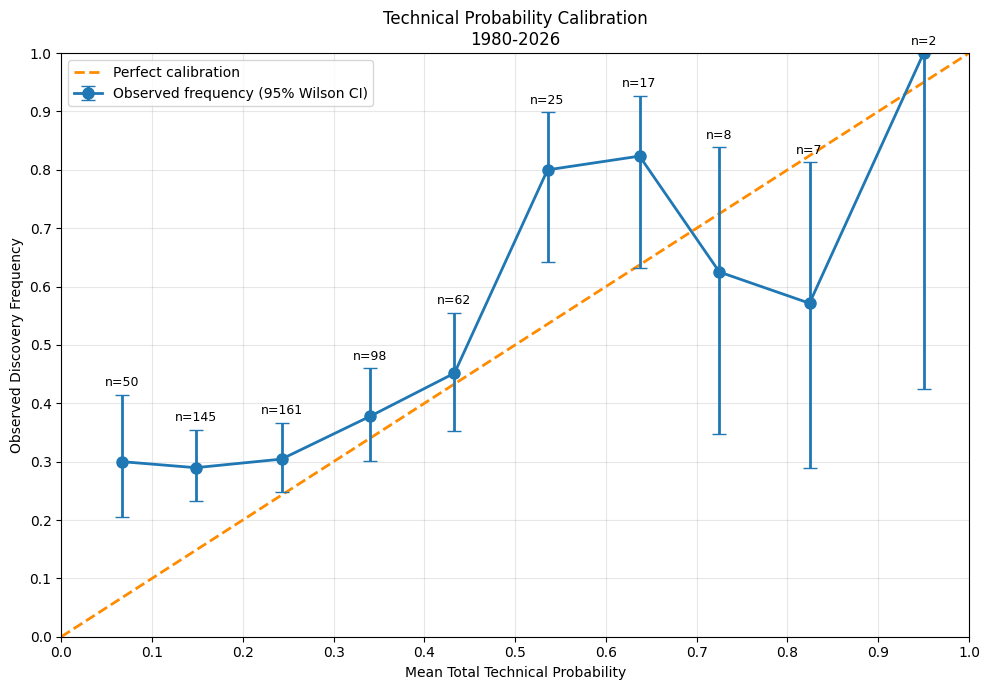

  bin_label  mean_predicted  observed_rate  ci_lower  ci_upper  wells
0   0.0-0.1        0.066672       0.300000  0.205926  0.414610     50
1   0.1-0.2        0.148017       0.289655  0.231992  0.355026    145
2   0.2-0.3        0.242625       0.304348  0.248335  0.366828    161
3   0.3-0.4        0.340009       0.377551  0.301308  0.460375     98
4   0.4-0.5        0.433145       0.451613  0.351846  0.555427     62
5   0.5-0.6        0.535680       0.800000  0.642303  0.899096     25
6   0.6-0.7        0.637059       0.823529  0.631014  0.927191     17
7   0.7-0.8        0.725000       0.625000  0.347971  0.838840      8
8   0.8-0.9        0.824286       0.571429  0.289458  0.813571      7
9   0.9-1.0        0.950000       1.000000  0.424987  1.000000      2


In [63]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

"""
This snippet computes and plots how well calibrated E&P companies on the NCS are w.r.t pre-drill technical discovery probability
"""

# =============================================================================
# USER SETTINGS
# =============================================================================

FILE = "data/2026-11 PrognosisResultData_Released.xlsx"

START_YEAR = 1980
END_YEAR = 2026

YEAR_COLUMN = "Evaluation Year"      # Replace with actual year column name

# =============================================================================
# LOAD DATA
# =============================================================================

df = pd.read_excel(FILE, sheet_name="Data")


def to_numeric(series):
    return pd.to_numeric(
        series.astype(str)
        .str.replace(",", ".", regex=False)
        .str.replace(r"[^0-9eE+\-.]", "", regex=True),
        errors="coerce",
    )


df["well"] = df["Well name"].astype(str).str.strip()

df["technical_probability"] = to_numeric(
    df["Probability Technical Total"]
)

df["discovery"] = (
    df["Discovery?"]
    .astype(str)
    .str.strip()
    .str.upper()
    .map({"YES": 1, "NO": 0})
)

# =============================================================================
# YEAR FILTER
# =============================================================================

df[YEAR_COLUMN] = pd.to_numeric(
    df[YEAR_COLUMN],
    errors="coerce"
)

df = df[
    (df[YEAR_COLUMN] >= START_YEAR)
    & (df[YEAR_COLUMN] <= END_YEAR)
].copy()

print(f"Rows after filtering: {len(df):,}")

# =============================================================================
# AGGREGATE TO ONE OBSERVATION PER WELL
# =============================================================================

# Technical probability:
# average AO per well

# Discovery:
# if any record for a well is YES -> discovery

well = (
    df.groupby("well", as_index=False)
    .agg(
        predicted_probability=(
            "technical_probability",
            "mean",
        ),
        discovery=(
            "discovery",
            "max",
        ),
    )
    .dropna()
)

print(f"Wells included: {len(well):,}")

# =============================================================================
# CREATE 0.1 PROBABILITY BINS
# =============================================================================

well["bin"] = np.minimum(
    np.floor(
        well["predicted_probability"] * 10
    ).astype(int),
    9,
)

cal = (
    well.groupby("bin", as_index=False)
    .agg(
        mean_predicted=(
            "predicted_probability",
            "mean",
        ),
        discoveries=(
            "discovery",
            "sum",
        ),
        wells=(
            "discovery",
            "size",
        ),
    )
)

cal["observed_rate"] = (
    cal["discoveries"] / cal["wells"]
)

# =============================================================================
# WILSON 95% CONFIDENCE INTERVALS
# =============================================================================

z = 1.959963984540054
z = 1.645

n = cal["wells"].astype(float)
p = cal["observed_rate"]

denom = 1 + z**2 / n

center = (
    p + z**2 / (2 * n)
) / denom

half_width = (
    z
    * np.sqrt(
        p * (1 - p) / n
        + z**2 / (4 * n**2)
    )
    / denom
)

cal["ci_lower"] = (
    center - half_width
).clip(0, 1)

cal["ci_upper"] = (
    center + half_width
).clip(0, 1)

# =============================================================================
# CREATE LABELS
# =============================================================================

cal["bin_label"] = [
    f"{i/10:.1f}-{(i+1)/10:.1f}"
    for i in cal["bin"]
]

# =============================================================================
# PLOT
# =============================================================================

fig, ax = plt.subplots(figsize=(10, 7))

# Perfect calibration line
ax.plot(
    [0, 1],
    [0, 1],
    "--",
    color="darkorange",
    linewidth=2,
    label="Perfect calibration",
)

# Wilson confidence intervals
yerr = np.vstack(
    [
        cal["observed_rate"] - cal["ci_lower"],
        cal["ci_upper"] - cal["observed_rate"],
    ]
)

ax.errorbar(
    cal["mean_predicted"],
    cal["observed_rate"],
    yerr=yerr,
    fmt="o-",
    color="tab:blue",
    ecolor="tab:blue",
    linewidth=2,
    capsize=5,
    markersize=8,
    label="Observed frequency (95% Wilson CI)",
)

# Annotate number of wells
for _, row in cal.iterrows():

    ax.annotate(
        f"n={int(row['wells'])}",
        (
            row["mean_predicted"],
            row["ci_upper"],
        ),
        xytext=(0, 6),
        textcoords="offset points",
        ha="center",
        fontsize=9,
    )

ax.set_xlim(0, 1)
ax.set_ylim(0, 1)

ax.set_xticks(
    np.arange(0, 1.01, 0.1)
)

ax.set_yticks(
    np.arange(0, 1.01, 0.1)
)

ax.grid(True, alpha=0.3)

ax.set_xlabel(
    "Mean Total Technical Probability"
)

ax.set_ylabel(
    "Observed Discovery Frequency"
)

ax.set_title(
    f"Technical Probability Calibration\n"
    f"{START_YEAR}-{END_YEAR}"
)

ax.legend()

plt.tight_layout()

plt.savefig(
    f"calibration_{START_YEAR}_{END_YEAR}.png",
    dpi=300,
)

plt.show()

# =============================================================================
# OPTIONAL: DISPLAY CALIBRATION TABLE
# =============================================================================

print(
    cal[
        [
            "bin_label",
            "mean_predicted",
            "observed_rate",
            "ci_lower",
            "ci_upper",
            "wells",
        ]
    ]
)


# Exploration: Recoverable Volume Calibration

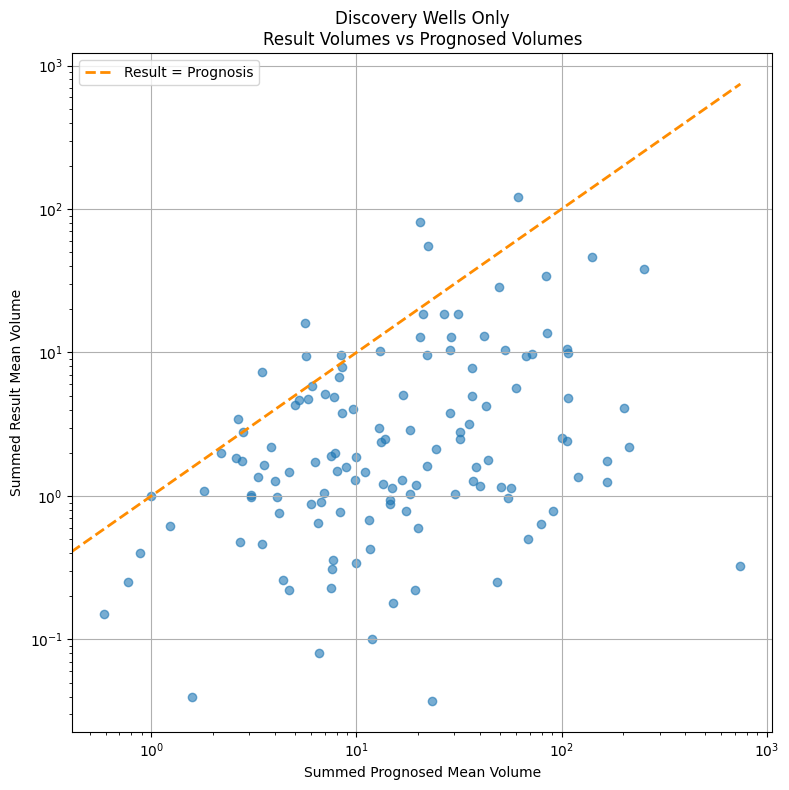

In [64]:
# =============================================================================
# PLOT 2
# Result vs Prognosis volumes (discovery wells only)
# =============================================================================

'''
This snippet computes and plots how well calibrated E&P companies on the NCS are w.r.t pre-drill recoverable volumes
'''

# Discovery wells
discovery_wells = set(
    df.loc[df["discovery"] == 1, "well"]
)

vol_df = df[
    df["well"].isin(discovery_wells)
].copy()

# Volume components
volume_columns = [
    "Recoverable Gas Main Mean",
    "Recover Oil Assoc Mean",
    "Recoverable Oil Main Mean",
    "Recover Gas Assoc Mean",
]

for col in volume_columns:
    vol_df[col] = to_numeric(vol_df[col])

vol_df["total_recoverable_mean"] = (
    vol_df[volume_columns]
    .sum(axis=1, min_count=1)
)

vol_df["type"] = (
    vol_df["Prognosis - Result"]
    .astype(str)
    .str.strip()
    .str.upper()
)

# Aggregate to well level
volumes = (
    vol_df
    .groupby(["well", "type"])["total_recoverable_mean"]
    .sum()
    .unstack()
)

volumes = volumes.dropna(
    subset=["PROGNOSIS", "RESULT"]
)

# -------------------------------------------------------------------------
# Plot
# -------------------------------------------------------------------------

fig, ax = plt.subplots(figsize=(8, 8))

ax.scatter(
    volumes["PROGNOSIS"],
    volumes["RESULT"],
    alpha=0.6,
)

max_value = np.nanmax(
    volumes[["PROGNOSIS", "RESULT"]].values
)

ax.plot(
    [0, max_value],
    [0, max_value],
    "--",
    color="darkorange",
    linewidth=2,
    label="Result = Prognosis",
)

ax.set_xlabel(
    "Summed Prognosed Mean Volume"
)

ax.set_ylabel(
    "Summed Result Mean Volume"
)

ax.set_title(
    "Discovery Wells Only\n"
    "Result Volumes vs Prognosed Volumes"
)

# Logarithmic axes 
ax.set_xscale("log") 
ax.set_yscale("log")

ax.legend()
ax.grid(True)

plt.tight_layout()

plt.savefig(
    "figures/result_vs_prognosis_discovery_wells.png",
    dpi=300,
)

plt.show()

# Exploration: In-place volume calibration

Wells included: 221


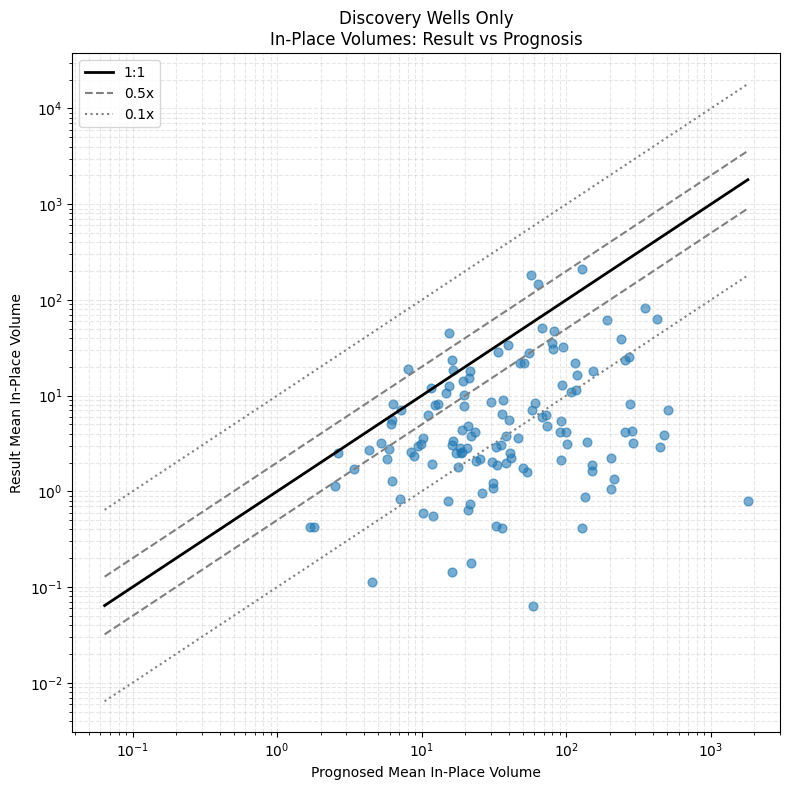

Correlation = 0.062

Totals:
type
PROGNOSIS    11341.969167
RESULT        1754.730929
dtype: float64


In [65]:
# =============================================================================
# IN-PLACE VOLUME PLOT (DISCOVERY WELLS ONLY)
# =============================================================================

"""
This snippet computes and plots how well calibrated E&P companies on the NCS are w.r.t pre-drill in-place volume estimates
"""

# Identify discovery wells

discovery_wells = set(
    df.loc[df["discovery"] == 1, "well"]
)

vol_df = df[
    df["well"].isin(discovery_wells)
].copy()

# -----------------------------------------------------------------------------
# Convert columns to numeric
# -----------------------------------------------------------------------------

volume_columns = [
    "Recoverable Gas Main Mean",
    "Recover Oil Assoc Mean",
    "Recoverable Oil Main Mean",
    "Recover Gas Assoc Mean",
]

for col in volume_columns:
    vol_df[col] = to_numeric(vol_df[col])

# -----------------------------------------------------------------------------
# Convert recoverable volumes to in-place volumes
#
# Oil RF  = 35%
# Gas RF  = 60%
# -----------------------------------------------------------------------------

vol_df["oil_recoverable"] = (
    vol_df["Recoverable Oil Main Mean"].fillna(0)
    + vol_df["Recover Oil Assoc Mean"].fillna(0)
)

vol_df["gas_recoverable"] = (
    vol_df["Recoverable Gas Main Mean"].fillna(0)
    + vol_df["Recover Gas Assoc Mean"].fillna(0)
)

vol_df["oil_inplace"] = (
    vol_df["oil_recoverable"] / 0.35
)

vol_df["gas_inplace"] = (
    vol_df["gas_recoverable"] / 0.60
)

vol_df["total_inplace"] = (
    vol_df["oil_inplace"]
    + vol_df["gas_inplace"]
)

# -----------------------------------------------------------------------------
# Forecast / Result flag
# -----------------------------------------------------------------------------

vol_df["type"] = (
    vol_df["Prognosis - Result"]
    .astype(str)
    .str.strip()
    .str.upper()
)

# -----------------------------------------------------------------------------
# Aggregate per well
# -----------------------------------------------------------------------------

inplace = (
    vol_df
    .groupby(
        ["well", "type"]
    )["total_inplace"]
    .sum()
    .unstack()
)

inplace = inplace.dropna(
    subset=["PROGNOSIS", "RESULT"]
)

print(
    f"Wells included: {len(inplace):,}"
)

# =============================================================================
# LOG-LOG SCATTER PLOT
# =============================================================================

plot_df = inplace.copy()

plot_df = plot_df[
    (plot_df["PROGNOSIS"] > 0)
    & (plot_df["RESULT"] > 0)
]

fig, ax = plt.subplots(
    figsize=(8, 8)
)

ax.scatter(
    plot_df["PROGNOSIS"],
    plot_df["RESULT"],
    alpha=0.6,
    s=40
)

# -----------------------------------------------------------------------------
# Reference lines
# -----------------------------------------------------------------------------

min_value = min(
    plot_df["PROGNOSIS"].min(),
    plot_df["RESULT"].min()
)

max_value = max(
    plot_df["PROGNOSIS"].max(),
    plot_df["RESULT"].max()
)

x = np.logspace(
    np.log10(min_value),
    np.log10(max_value),
    200
)

# 1:1
ax.plot(
    x,
    x,
    color="black",
    linewidth=2,
    label="1:1"
)

# factor 2 low
ax.plot(
    x,
    x / 2,
    "--",
    color="gray",
    label="0.5x"
)

# factor 2 high
ax.plot(
    x,
    x * 2,
    "--",
    color="gray"
)

# factor 10 low
ax.plot(
    x,
    x / 10,
    ":",
    color="gray",
    label="0.1x"
)

# factor 10 high
ax.plot(
    x,
    x * 10,
    ":",
    color="gray"
)

# -----------------------------------------------------------------------------
# Log axes
# -----------------------------------------------------------------------------

ax.set_xscale("log")
ax.set_yscale("log")

ax.set_xlabel(
    "Prognosed Mean In-Place Volume"
)

ax.set_ylabel(
    "Result Mean In-Place Volume"
)

ax.set_title(
    "Discovery Wells Only\n"
    "In-Place Volumes: Result vs Prognosis"
)

ax.grid(
    which="both",
    linestyle="--",
    alpha=0.3
)

ax.legend()

plt.tight_layout()
        
plt.savefig(
    "figures/inplace_result_vs_prognosis_loglog.png",
    dpi=300
)

plt.show()

# =============================================================================
# SUMMARY STATISTICS
# =============================================================================

correlation = (
    plot_df[
        ["PROGNOSIS", "RESULT"]
    ]
    .corr()
    .iloc[0, 1]
)

print(
    f"Correlation = {correlation:.3f}"
)

print(
    "\nTotals:"
)

print(
    plot_df[
        ["PROGNOSIS", "RESULT"]
    ].sum()
)


Number of fields: 36
Log-log correlation: 0.572
Median reserve/in-place ratio: 0.319


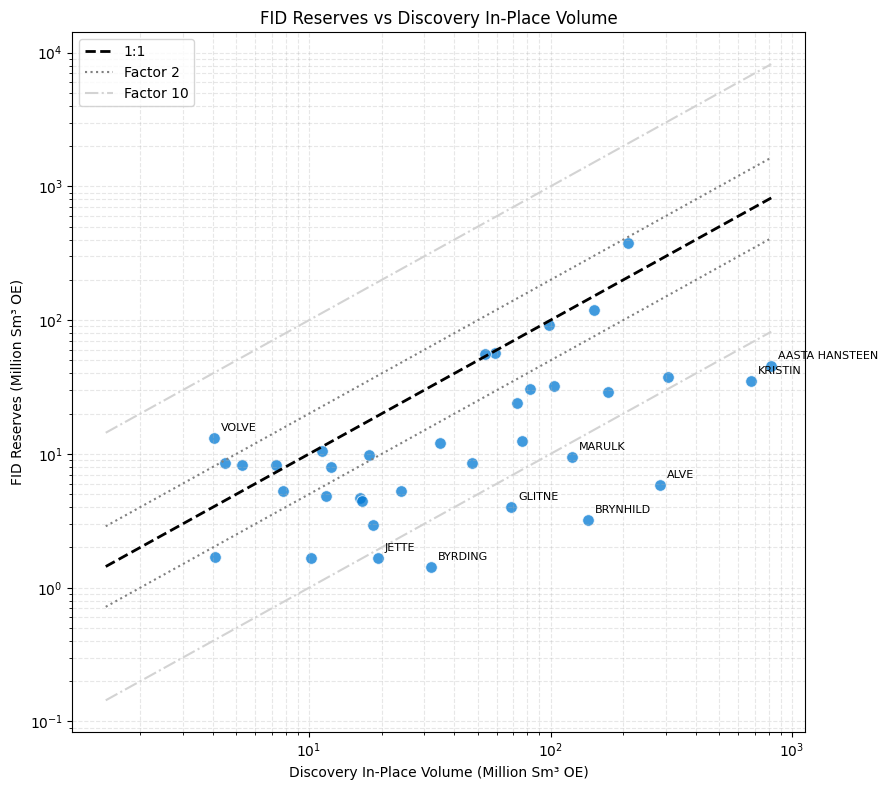

In [66]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

"""
This snippet computes and plots how post-drill in-place estimates on the NCS relate to sanctioned resources at FID
"""

# ------------------------------------------------------------------
# Load linked dataset
# ------------------------------------------------------------------

df = pd.read_excel(
    "data/fid_reserves_vs_discovery_inplace_total.xlsx"
)

# ------------------------------------------------------------------
# Total discovery in-place and total FID reserves
# ------------------------------------------------------------------

df["discovery_total_inplace"] = (
    df["discovery_oil_inplace"]
    + df["discovery_gas_inplace"]
)

df["fid_total_reserves"] = (
    df["fid_oil_reserves"]
    + df["fid_gas_reserves"]
)

# Keep only positive values for log scale
plot_df = df[
    (df["discovery_total_inplace"] > 0)
    & (df["fid_total_reserves"] > 0)
].copy()

# ------------------------------------------------------------------
# Statistics
# ------------------------------------------------------------------

plot_df["reserve_to_inplace_ratio"] = (
    plot_df["fid_total_reserves"]
    / plot_df["discovery_total_inplace"]
)

log_corr = np.corrcoef(
    np.log10(plot_df["discovery_total_inplace"]),
    np.log10(plot_df["fid_total_reserves"])
)[0, 1]

median_ratio = (
    plot_df["reserve_to_inplace_ratio"]
    .median()
)

print(
    f"Number of fields: {len(plot_df)}"
)
print(
    f"Log-log correlation: {log_corr:.3f}"
)
print(
    f"Median reserve/in-place ratio: "
    f"{median_ratio:.3f}"
)

# ------------------------------------------------------------------
# Plot
# ------------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(9, 8),
    facecolor="white"
)

ax.scatter(
    plot_df["discovery_total_inplace"],
    plot_df["fid_total_reserves"],
    s=70,
    alpha=0.75,
    color="#0078D4",
    edgecolor="white",
    linewidth=0.7,
)

# ------------------------------------------------------------------
# Reference lines
# ------------------------------------------------------------------

min_value = min(
    plot_df["discovery_total_inplace"].min(),
    plot_df["fid_total_reserves"].min()
)

max_value = max(
    plot_df["discovery_total_inplace"].max(),
    plot_df["fid_total_reserves"].max()
)

x = np.logspace(
    np.log10(min_value),
    np.log10(max_value),
    300
)

# 1:1 line
ax.plot(
    x,
    x,
    "--",
    color="black",
    linewidth=2,
    label="1:1"
)

# Factor 2 lines
ax.plot(
    x,
    x * 2,
    ":",
    color="gray",
    linewidth=1.5,
    label="Factor 2"
)

ax.plot(
    x,
    x / 2,
    ":",
    color="gray",
    linewidth=1.5,
)

# Factor 10 lines
ax.plot(
    x,
    x * 10,
    "-.",
    color="lightgray",
    linewidth=1.5,
    label="Factor 10"
)

ax.plot(
    x,
    x / 10,
    "-.",
    color="lightgray",
    linewidth=1.5,
)

# ------------------------------------------------------------------
# Label outliers (optional)
# ------------------------------------------------------------------

plot_df["ratio"] = (
    plot_df["fid_total_reserves"]
    / plot_df["discovery_total_inplace"]
)

outliers = plot_df[
    (plot_df["ratio"] > 2)
    | (plot_df["ratio"] < 0.1)
]

for _, row in outliers.iterrows():

    ax.annotate(
        row["Feltnavn"],
        (
            row["discovery_total_inplace"],
            row["fid_total_reserves"],
        ),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=8,
    )

# ------------------------------------------------------------------
# Formatting
# ------------------------------------------------------------------

ax.set_xscale("log")
ax.set_yscale("log")

ax.set_xlabel(
    "Discovery In-Place Volume (Million Sm³ OE)"
)

ax.set_ylabel(
    "FID Reserves (Million Sm³ OE)"
)

ax.set_title(
    "FID Reserves vs Discovery In-Place Volume"
)

ax.grid(
    which="both",
    linestyle="--",
    alpha=0.3
)

ax.legend()

plt.tight_layout()

plt.savefig(
    "figures/fid_reserves_vs_discovery_inplace_loglog.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()


   production_year   RCF_P10    RCF_P50    RCF_P90
0                1  0.019381   0.489229   2.079504
1                2  0.369317   2.125480   5.574938
2                3  0.814546   4.021062   7.672837
3                4  1.555456   5.783213  10.464861
4                5  2.109073   7.057736  12.582289
5                6  2.236839   8.061114  14.536689
6                7  2.618704   8.948815  16.859805
7                8  3.200157   9.908983  18.229385
8                9  3.586141  10.642511  19.968217
9               10  3.649759  11.429441  22.242593


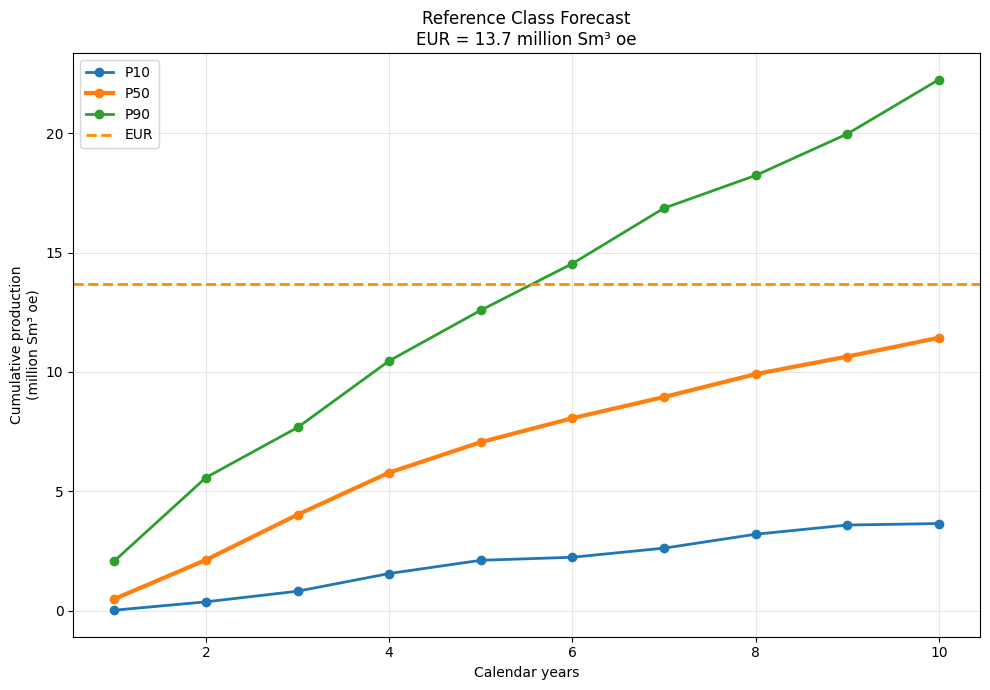

In [67]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

"""
This function creates a reference class forecast based on actual production history, resource estimates over time and FID dates.
Everything is based on open source data on the NCS.
"""

def reference_class_forecast(
    production_file,
    pdo_file,
    reserves_file,
    eur,
    n_years=10
):
    """
    Create a Reference Class Forecast (RCF) production profile
    from historical field performance.

    Parameters
    ----------
    production_file : str
        SODIR field_production_yearly export

    pdo_file : str
        field_pdo_hst export

    reserves_file : str
        RCB reserves file

    eur : float
        Expected Ultimate Recovery (million Sm3 oe) for a new field

    n_years : int
        Number of years to forecast

    Returns
    -------
    percentile_table : DataFrame
    forecast_table : DataFrame
    """

    # ------------------------------------------------------------
    # Load data
    # ------------------------------------------------------------

    prod = pd.read_excel(
        production_file,
        sheet_name="field_production_yearly"
    )

    pdo = pd.read_excel(
        pdo_file,
        sheet_name="field_pdo_hst"
    )

    reserves = pd.read_excel(
        reserves_file
    )

    # ------------------------------------------------------------
    # FID reserves lookup
    # ------------------------------------------------------------

    pdo["approval_date"] = pd.to_datetime(
        pdo["Dato PUD godkjent"],
        errors="coerce"
    )

    pdo["type_clean"] = (
        pdo["Type"]
        .astype(str)
        .str.upper()
        .str.strip()
    )

    pdo = (
        pdo[
            pdo["type_clean"].isin(
                ["PDO", "PDO EXEMPTION"]
            )
        ]
        .sort_values("approval_date")
        .drop_duplicates("NPDID felt")
    )

    pdo = pdo.rename(
        columns={
            "NPDID felt": "field_id",
            "Feltnavn": "field"
        }
    )

    rows = []

    for _, row in pdo.iterrows():

        approval_year = row["approval_date"].year

        tmp = reserves[
            reserves["field_id"] == row["field_id"]
        ].copy()

        if len(tmp) == 0:
            continue

        tmp["year_gap"] = (
            tmp["year"] - approval_year
        ).abs()

        best = (
            tmp
            .sort_values(
                ["year_gap", "year"]
            )
            .iloc[0]
        )

        rows.append(
            {
                "field": row["field"],
                "field_key": str(
                    row["field"]
                ).strip().upper(),
                "fid_reserves":
                    best["oil_reserves"]
                    + best["gas_reserves"]
            }
        )

    fid = pd.DataFrame(rows)

    # ------------------------------------------------------------
    # Production history
    # ------------------------------------------------------------

    prod["field_key"] = (
        prod["Felt (Funn)"]
        .astype(str)
        .str.strip()
        .str.upper()
    )

    prod["year"] = pd.to_numeric(
        prod["År"],
        errors="coerce"
    )

    prod["annual_prod"] = pd.to_numeric(
        prod["Netto – oljeekvivalenter \n[mill Sm3]"],
        errors="coerce"
    )

    prod = (
        prod.groupby(
            ["field_key", "year"],
            as_index=False
        )["annual_prod"]
        .sum()
    )

    data = prod.merge(
        fid,
        on="field_key",
        how="inner"
    )

    data = data[
        data["fid_reserves"] > 0
    ].copy()

    # ------------------------------------------------------------
    # First production year
    # ------------------------------------------------------------

    starts = (
        data[data["annual_prod"] > 0]
        .groupby("field_key")["year"]
        .min()
        .rename("start_year")
    )

    data = data.merge(
        starts,
        on="field_key"
    )

    max_year = (
        data["year"].max()
    )

    eligible = starts[
        starts + (n_years - 1)
        <= max_year
    ].index

    data = data[
        data["field_key"].isin(
            eligible
        )
    ]

    data["production_year"] = (
        data["year"]
        - data["start_year"]
        + 1
    )

    data = data[
        data["production_year"]
        .between(1, n_years)
    ]

    # ------------------------------------------------------------
    # Complete trajectories
    # ------------------------------------------------------------

    trajectories = []

    for field_key, grp in data.groupby(
        "field_key"
    ):

        first_row = grp.iloc[0]

        annual = (
            grp.set_index(
                "production_year"
            )["annual_prod"]
        )

        cumulative = 0

        for yr in range(
            1,
            n_years + 1
        ):

            annual_prod = annual.get(
                yr,
                0
            )

            cumulative += annual_prod

            trajectories.append(
                {
                    "field":
                        first_row["field"],
                    "production_year":
                        yr,
                    "cum_fraction":
                        cumulative
                        / first_row[
                            "fid_reserves"
                        ]
                }
            )

    traj = pd.DataFrame(
        trajectories
    )

    # ------------------------------------------------------------
    # Percentiles
    # ------------------------------------------------------------

    percentiles = (
        traj.groupby(
            "production_year"
        )["cum_fraction"]
        .quantile(
            [0.10, 0.50, 0.90]
        )
        .unstack()
        .rename(
            columns={
                0.10: "P10",
                0.50: "P50",
                0.90: "P90"
            }
        )
        .reset_index()
    )

    # ------------------------------------------------------------
    # Reference Class Forecast
    # ------------------------------------------------------------

    forecast = percentiles.copy()

    forecast["RCF_P10"] = (
        forecast["P10"] * eur
    )

    forecast["RCF_P50"] = (
        forecast["P50"] * eur
    )

    forecast["RCF_P90"] = (
        forecast["P90"] * eur
    )

    # ------------------------------------------------------------
    # Plot
    # ------------------------------------------------------------

    fig, ax = plt.subplots(
        figsize=(10, 7)
    )

    ax.plot(
        forecast["production_year"],
        forecast["RCF_P10"],
        "o-",
        linewidth=2,
        label="P10"
    )

    ax.plot(
        forecast["production_year"],
        forecast["RCF_P50"],
        "o-",
        linewidth=3,
        label="P50"
    )

    ax.plot(
        forecast["production_year"],
        forecast["RCF_P90"],
        "o-",
        linewidth=2,
        label="P90"
    )

    ax.axhline(
        eur,
        color="darkorange",
        linestyle="--",
        linewidth=2,
        label="EUR"
    )

    ax.set_xlabel(
        "Calendar years"
    )

    ax.set_ylabel(
        "Cumulative production\n"
        "(million Sm³ oe)"
    )

    ax.set_title(
        f"Reference Class Forecast\n"
        f"EUR = {eur:.1f} million Sm³ oe"
    )

    ax.grid(True, alpha=0.3)

    ax.legend()

    plt.tight_layout()

    return (
        percentiles,
        forecast
    )


# ==============================================================
# EXAMPLE
# ==============================================================

EUR = 13.7 # Volve example

percentiles, forecast = (
    reference_class_forecast(
        production_file=
            "data/field_production_yearly.xlsx",
        pdo_file=
            "data/field_pdo_hst.xlsx",
        reserves_file=
            "data/RCB_reserves.xlsx",
        eur=EUR,
        n_years=10
    )
)

print(
    forecast[
        [
            "production_year",
            "RCF_P10",
            "RCF_P50",
            "RCF_P90"
        ]
    ]
)
